# SVPA Gauge Forecast Regression

Goal: For every flood event where the **Carnation** USGS gauge (`12149000`) crests
**≥ 51 ft** (its flood/yellow stage), regress each SVPA gauge's crest stage against
its USGS *predictor* gauge's crest stage. The two USGS gauges with NWRFC forecasts
— **Falls** (`12144500`, RM 38) and **Carnation** (`12149000`, RM 22) — are the
predictors, so a good fit lets us turn an NWRFC forecast into a forecast for each
SVPA gauge.

Predictor split (by river mile of the SVPA gauge):

| SVPA river mile | Predictor |
|---|---|
| > 29 | Falls (RM 38) |
| ≤ 29 | Carnation (RM 22) |

Each scatter point is one flood event; the fit line is a simple linear regression.
Hover a point to see its **event date** so outliers can be traced back to a specific
flood and checked for bad data.

> SVPA-6 / SVPA-6B are intentionally skipped. A per-gauge bad-crest exclusion layer
> (like `data_files/historic-crest-overrides.json`) is a planned follow-up and is
> **not** applied here yet.

Notebook assumes the working directory is `notebooks/` (paths are relative with `../`),
matching `crest-analysis.ipynb`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from sklearn import linear_model

# Emit a static PNG alongside the interactive view so charts render on GitHub.
# Falls back to interactive-only if kaleido is missing in the active kernel
# (e.g. a kernel other than this project's .venv).
try:
    import kaleido  # noqa: F401
    pio.renderers.default = "plotly_mimetype+png"
except ImportError:
    pio.renderers.default = "plotly_mimetype"

CARNATION_ID = "12149000"   # RM 22, NWRFC forecast
FALLS_ID = "12144500"       # RM 38, NWRFC forecast
EVENT_THRESHOLD_FT = 51.0   # Carnation flood / yellow stage
MATCH_WINDOW = pd.Timedelta(hours=24)
SKIP_GAUGES = {"SVPA-6", "SVPA-6B"}

ROOT = Path("..")

with open(ROOT / "locations.json") as f:
    locations = json.load(f)["locations"]

river_mile = {loc["id"]: loc.get("riverMile") for loc in locations}
loc_name = {loc["id"]: loc["name"] for loc in locations}
with open(ROOT / "data_files" / "forecast-crest-corrections.json") as f:
    _corrections = json.load(f)
# {gauge_id: {excluded event_date, ...}}; keys starting with "__" are docs.
EXCLUSIONS = {
    gid: set(entry.get("exclude", {}))
    for gid, entry in _corrections.items() if not gid.startswith("__")
}

river_mile[FALLS_ID], river_mile[CARNATION_ID]

(38, 22)

In [2]:
def load_crests(source: str, gauge_id: str) -> pd.DataFrame:
    """Load a per-gauge crest CSV (tab-delimited) with utc parsed and sorted."""
    path = ROOT / "crests" / source / gauge_id / f"{source}-{gauge_id}-crests.csv"
    df = pd.read_csv(path, sep="\t")
    df["utc"] = pd.to_datetime(df["utc"])
    return df.sort_values("utc").reset_index(drop=True)

carnation = load_crests("usgs", CARNATION_ID)
falls = load_crests("usgs", FALLS_ID)

events = carnation[carnation["stage"] >= EVENT_THRESHOLD_FT].copy()
print(f"{len(events)} Carnation events >= {EVENT_THRESHOLD_FT} ft "
      f"(of {len(carnation)} detected crests)")
events[["utc", "stage", "discharge"]].head()

105 Carnation events >= 51.0 ft (of 478 detected crests)


,utc,stage,discharge
5,2007-12-04 18:00:00,56.99,32100.0
14,2008-05-18 16:45:00,53.48,18100.0
15,2008-05-21 07:15:00,52.35,15300.0
27,2008-11-08 07:00:00,57.24,34100.0
28,2008-11-13 15:45:00,60.49,63100.0


In [3]:
def match_crest(df: pd.DataFrame, ref_time: pd.Timestamp, direction: str,
                window: pd.Timedelta = MATCH_WINDOW):
    """Return the highest crest in df within `window` of ref_time.

    direction='after'  -> search (ref_time, ref_time + window]   (target downstream
                          of predictor, so it crests later)
    direction='before' -> search [ref_time - window, ref_time)   (target upstream,
                          crests earlier)
    Returns a row (Series) or None.
    """
    if direction == "after":
        mask = (df["utc"] > ref_time) & (df["utc"] <= ref_time + window)
    elif direction == "before":
        mask = (df["utc"] >= ref_time - window) & (df["utc"] < ref_time)
    else:
        raise ValueError(direction)
    window_df = df[mask]
    if window_df.empty:
        return None
    return window_df.loc[window_df["stage"].idxmax()]


def build_pairs(target_id: str, target_correction=None, apply_exclusions=True):
    """Pair predictor stage with target SVPA stage for each qualifying event.

    Returns a DataFrame with columns: event_date, predictor_stage, target_stage.
    """
    target_rm = river_mile[target_id]
    if target_rm is not None and target_rm > 29:
        predictor_id, predictor_rm, predictor_df = FALLS_ID, river_mile[FALLS_ID], falls
    else:
        predictor_id, predictor_rm, predictor_df = CARNATION_ID, river_mile[CARNATION_ID], carnation

    target_df = load_crests("svpa", target_id)
    if target_correction is not None:
        target_df = target_correction(target_df)
    # Predictor upstream of target -> target crests later -> look AFTER predictor crest.
    direction = "after" if predictor_rm > target_rm else "before"

    rows = []
    for _, ev in events.iterrows():
        # Predictor crest for this event.
        if predictor_id == CARNATION_ID:
            t_pred, s_pred = ev["utc"], ev["stage"]
        else:
            # Falls is upstream of Carnation, so its crest precedes the event.
            pred_crest = match_crest(predictor_df, ev["utc"], "before")
            if pred_crest is None:
                continue
            t_pred, s_pred = pred_crest["utc"], pred_crest["stage"]

        target_crest = match_crest(target_df, t_pred, direction)
        if target_crest is None:
            continue
        rows.append({
            "event_date": ev["utc"].date().isoformat(),
            "predictor_stage": float(s_pred),
            "target_stage": float(target_crest["stage"]),
        })

    pairs = pd.DataFrame(rows)
    if apply_exclusions and not pairs.empty:
        excluded = EXCLUSIONS.get(target_id, set())
        pairs = pairs[~pairs["event_date"].isin(excluded)].reset_index(drop=True)
    return pairs, predictor_id, direction

pairs, pid, d = build_pairs("SVPA-25")
print(f"SVPA-25 predictor={pid} direction={d} -> {len(pairs)} paired events")
pairs.head()

SVPA-25 predictor=12149000 direction=before -> 25 paired events


,event_date,predictor_stage,target_stage
0,2021-01-03,52.55,67.26
1,2021-01-14,55.33,69.02
2,2021-02-23,53.03,67.73
3,2021-10-29,55.26,69.43
4,2021-11-13,57.12,71.57


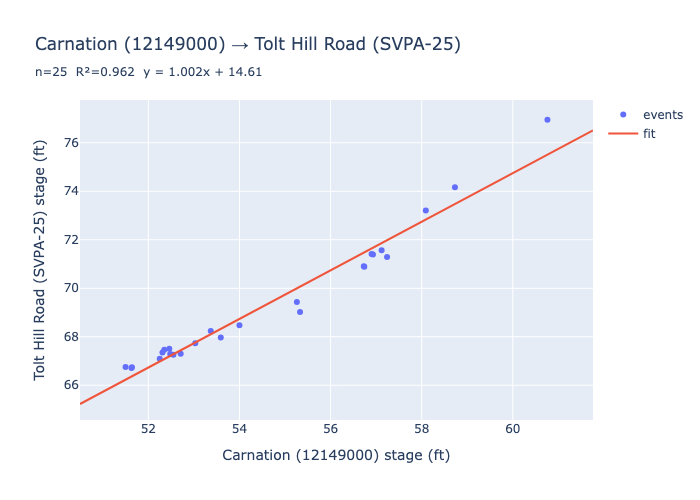

In [4]:
def build_model(pairs: pd.DataFrame):
    X = pairs["predictor_stage"].to_numpy().reshape(-1, 1)
    y = pairs["target_stage"].to_numpy()
    regr = linear_model.LinearRegression().fit(X, y)
    return regr, regr.score(X, y)


def plot_model(regr, pairs, predictor_id, target_id, score):
    Xv = pairs["predictor_stage"].to_numpy()
    yv = pairs["target_stage"].to_numpy()
    xfit = np.linspace(Xv.min() - 1, Xv.max() + 1, 200)
    yfit = regr.predict(xfit[:, None])

    pred_label = f"{loc_name.get(predictor_id, predictor_id)} ({predictor_id})"
    targ_label = f"{loc_name.get(target_id, target_id)} ({target_id})"
    title = (f"{pred_label} → {targ_label}<br>"
             f"<sub>n={len(pairs)}  R²={score:.3f}  "
             f"y = {regr.coef_[0]:.3f}x + {regr.intercept_:.2f}</sub>")

    fig = go.Figure()
    fig.add_scatter(
        x=Xv, y=yv, mode="markers", name="events",
        text=pairs["event_date"],
        hovertemplate=(f"{pred_label}: %{{x:.2f}} ft<br>"
                       f"{targ_label}: %{{y:.2f}} ft<br>%{{text}}<extra></extra>"),
    )
    fig.add_scatter(x=xfit, y=yfit, mode="lines", name="fit", hoverinfo="skip")
    fig.update_layout(title=title, xaxis_title=f"{pred_label} stage (ft)",
                      yaxis_title=f"{targ_label} stage (ft)", height=500)
    fig.show()

regr, score = build_model(pairs)
plot_model(regr, pairs, pid, "SVPA-25", score)

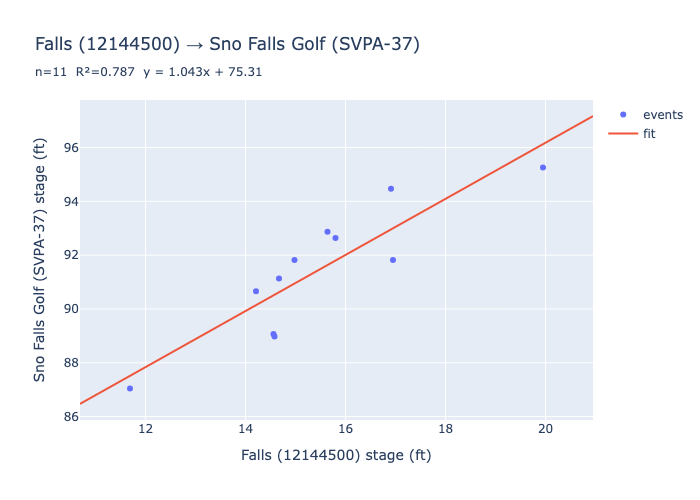

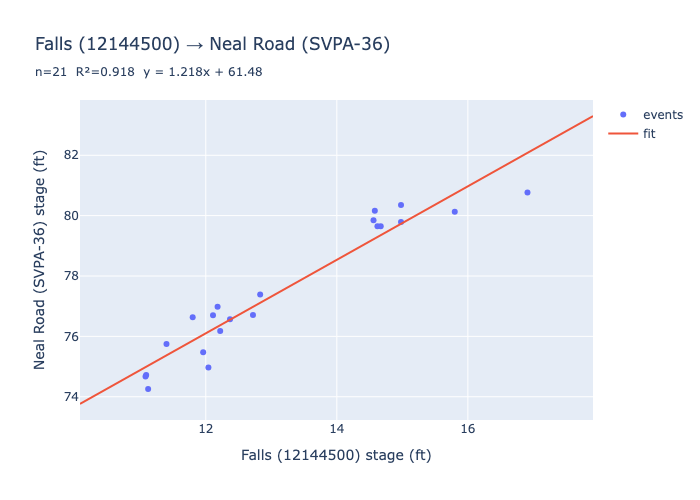

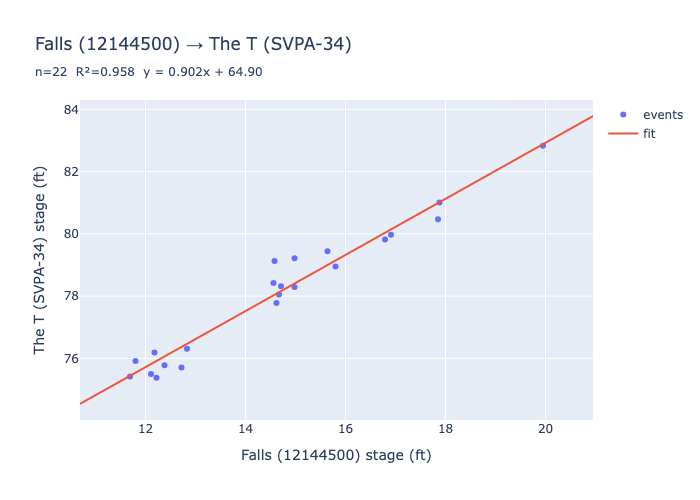

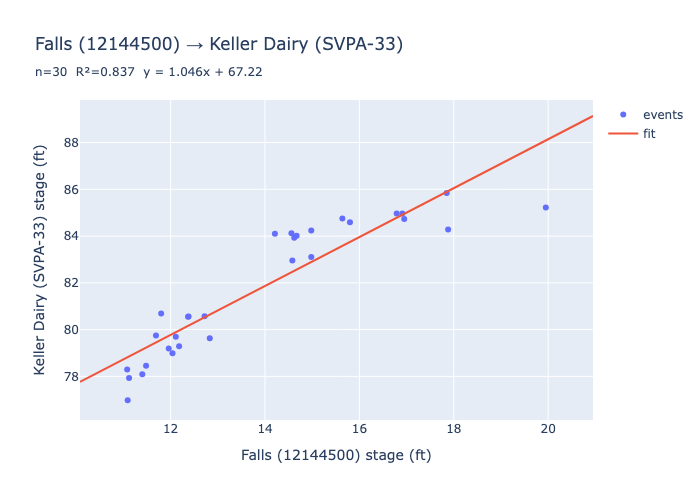

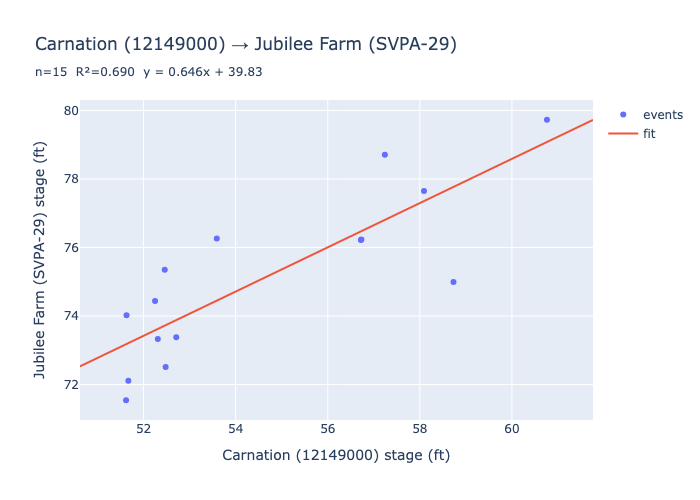

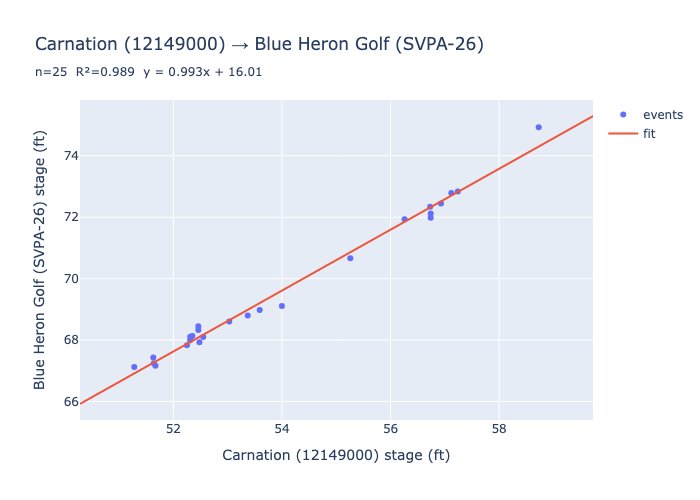

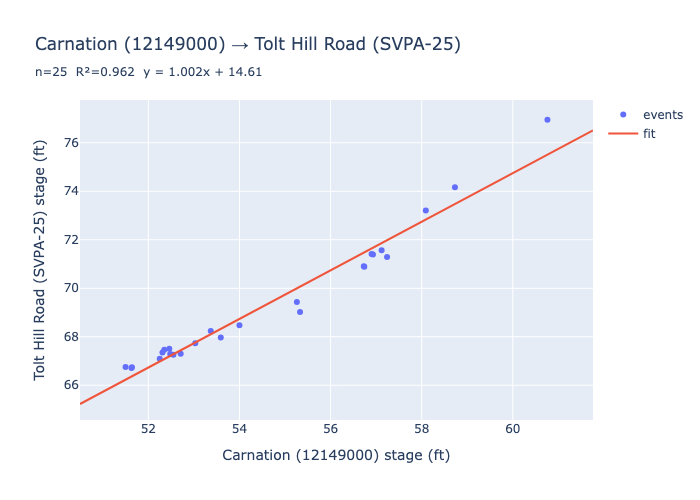

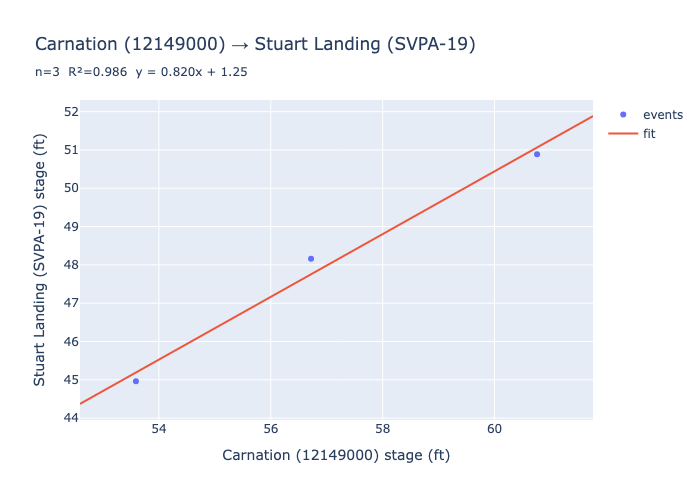

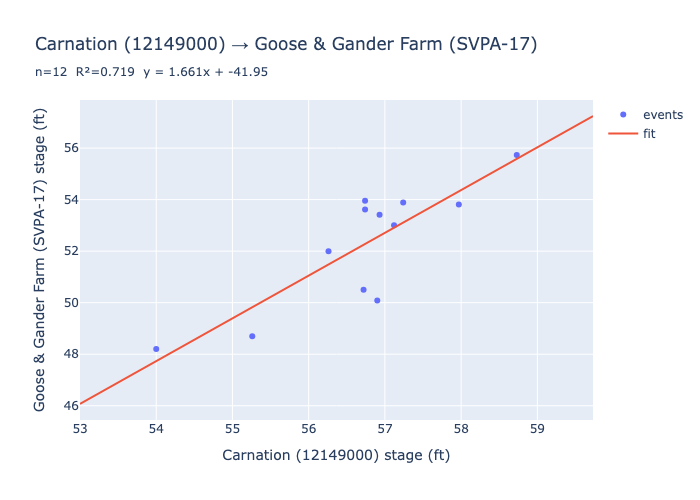

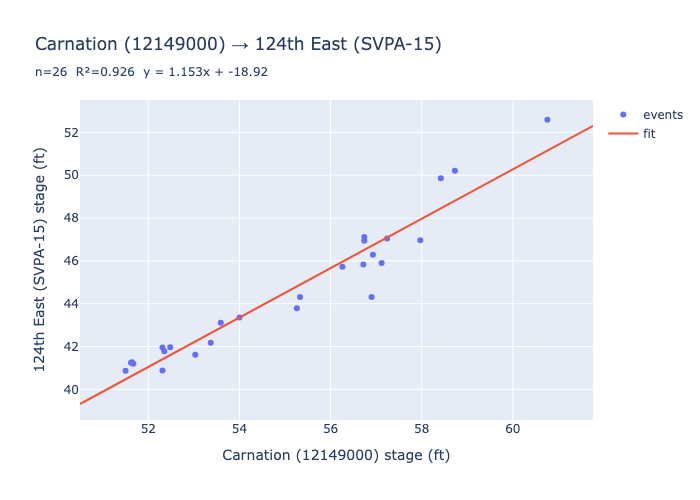

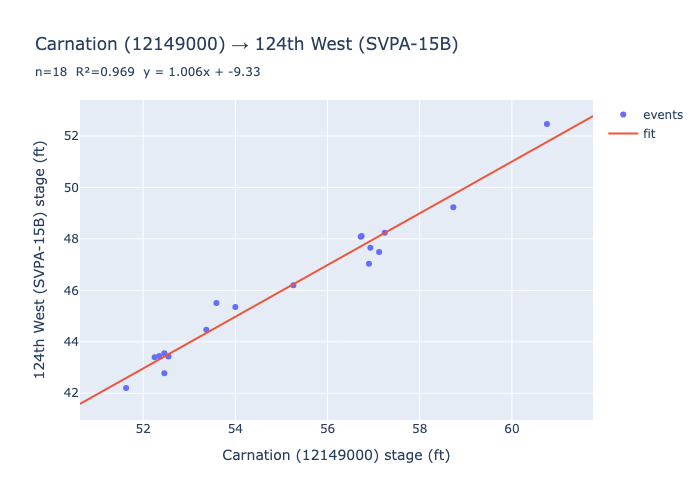

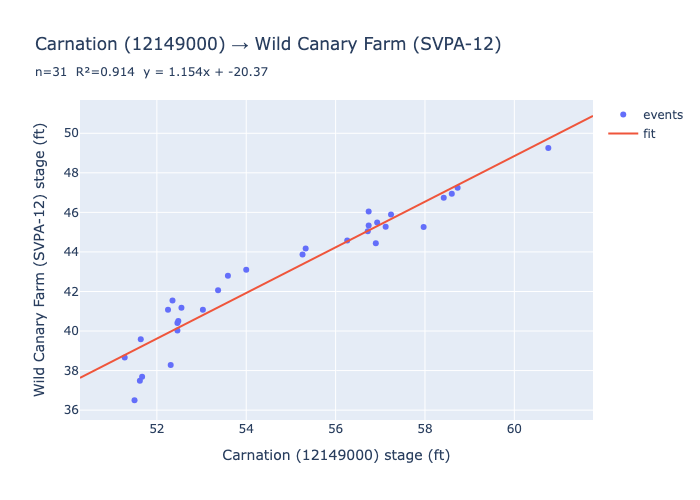

,gauge,predictor,n,r2
0,SVPA-37,12144500,11,0.787
1,SVPA-36,12144500,21,0.918
2,SVPA-34,12144500,22,0.958
3,SVPA-33,12144500,30,0.837
4,SVPA-29,12149000,15,0.690
5,SVPA-26,12149000,25,0.989
6,SVPA-25,12149000,25,0.962
7,SVPA-19,12149000,3,0.986
8,SVPA-17,12149000,12,0.719
9,SVPA-15,12149000,26,0.926


In [5]:
svpa_gauges = [loc["id"] for loc in locations
               if loc["source"] == "SVPA" and loc["id"] not in SKIP_GAUGES]

summary = []
for gid in svpa_gauges:
    pairs, predictor_id, direction = build_pairs(gid)
    if len(pairs) < 2:
        print(f"{gid}: only {len(pairs)} paired events — skipping plot")
        summary.append({"gauge": gid, "predictor": predictor_id,
                        "n": len(pairs), "r2": np.nan})
        continue
    regr, score = build_model(pairs)
    summary.append({"gauge": gid, "predictor": predictor_id,
                    "n": len(pairs), "r2": round(score, 3)})
    plot_model(regr, pairs, predictor_id, gid, score)

pd.DataFrame(summary)

## Probability of reaching redStage vs predictor stage

For each SVPA gauge we already have a strong linear fit `target ≈ slope·predictor + intercept`.
Treating the fit residuals as Gaussian, the probability that the gauge reaches its
**redStage** for a given predictor stage *x* is

$$P(\text{target} \ge \text{redStage} \mid x) = \Phi\!\left(\frac{\hat{y}(x) - \text{redStage}}{\sigma}\right)$$

where $\hat{y}(x)$ is the regression prediction and $\sigma$ is the residual standard
error of the fit ($\sqrt{\text{SSE}/(n-2)}$). `redStage` values come from the Floodzilla
`APIGetLocationInfo` endpoint. The dots show the actual events (at y=1 if they reached
redStage, y=0 otherwise) so you can sanity-check the curve and still spot outliers.

In [6]:
import requests
from scipy.stats import norm

_info = requests.get(
    "https://floodzilla.com/api/client/APIGetLocationInfo?regionId=1", timeout=30
).json()
red_stage = {g["id"]: g.get("redStage") for g in _info if g.get("redStage") is not None}
{k: red_stage[k] for k in svpa_gauges if k in red_stage}

{'SVPA-37': 88.6,
 'SVPA-36': 74.12,
 'SVPA-34': 75.85,
 'SVPA-33': 81.95,
 'SVPA-29': 75.67,
 'SVPA-26': 66.51,
 'SVPA-25': 68.43,
 'SVPA-19': 43.94,
 'SVPA-17': 44.49,
 'SVPA-15': 42.91,
 'SVPA-15B': 45.25,
 'SVPA-12': 36.22}

In [7]:
def residual_sigma(regr, pairs):
    """Residual standard error of the linear fit: sqrt(SSE / (n - 2))."""
    X = pairs["predictor_stage"].to_numpy().reshape(-1, 1)
    y = pairs["target_stage"].to_numpy()
    resid = y - regr.predict(X)
    n = len(y)
    return float(np.sqrt(np.sum(resid ** 2) / (n - 2))) if n > 2 else np.nan


def plot_probability_curve(regr, pairs, predictor_id, target_id, red):
    sigma = residual_sigma(regr, pairs)
    if not np.isfinite(sigma) or sigma == 0:
        print(f"{target_id}: cannot estimate residual sigma (n={len(pairs)}) — skipping")
        return None

    Xv = pairs["predictor_stage"].to_numpy()
    xline = np.linspace(Xv.min() - 1, Xv.max() + 3, 300)
    yhat = regr.predict(xline[:, None])
    prob = norm.cdf((yhat - red) / sigma)

    # Predictor stage giving each probability of reaching redStage.
    # P = 0.5 when yhat == red  ->  x = (red - intercept) / slope.
    slope, intercept = regr.coef_[0], regr.intercept_
    def x_for_prob(p):
        return (red + norm.ppf(p) * sigma - intercept) / slope
    x50, x90 = x_for_prob(0.5), x_for_prob(0.9)

    pred_label = f"{loc_name.get(predictor_id, predictor_id)} ({predictor_id})"
    targ_label = f"{loc_name.get(target_id, target_id)} ({target_id})"
    hit = (pairs["target_stage"] >= red).astype(int)

    fig = go.Figure()
    fig.add_scatter(x=xline, y=prob, mode="lines", name="P(reach redStage)",
                    hovertemplate=f"{pred_label}: %{{x:.2f}} ft<br>"
                                  "P=%{y:.0%}<extra></extra>")
    fig.add_scatter(x=Xv, y=hit, mode="markers", name="events",
                    marker=dict(color=hit, colorscale=[[0, "#1f77b4"], [1, "#d62728"]],
                                symbol="circle-open", size=8),
                    text=pairs["event_date"],
                    hovertemplate=(f"{pred_label}: %{{x:.2f}} ft<br>"
                                   f"{targ_label} reached red: %{{y}}<br>"
                                   "%{text}<extra></extra>"))
    for p, xv, dash in [(0.5, x50, "dash"), (0.9, x90, "dot")]:
        fig.add_vline(x=xv, line=dict(color="gray", dash=dash))
    fig.update_layout(
        title=(f"P({targ_label} ≥ redStage {red} ft) vs {pred_label}<br>"
               f"<sub>n={len(pairs)}  σ={sigma:.2f} ft  "
               f"P50 @ {x50:.1f} ft  P90 @ {x90:.1f} ft</sub>"),
        xaxis_title=f"{pred_label} stage (ft)",
        yaxis_title="probability of reaching redStage",
        yaxis=dict(range=[-0.05, 1.05], tickformat=".0%"), height=500)
    fig.show()
    return {"gauge": target_id, "predictor": predictor_id, "redStage": red,
            "sigma": round(sigma, 2), "pred_stage_P50": round(x50, 1),
            "pred_stage_P90": round(x90, 1)}

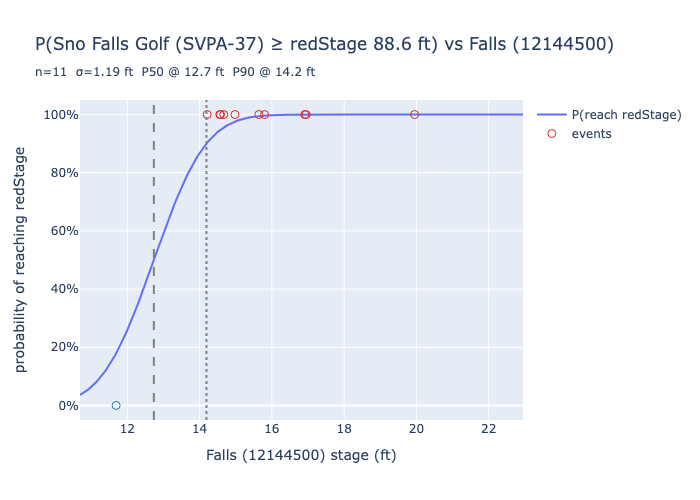

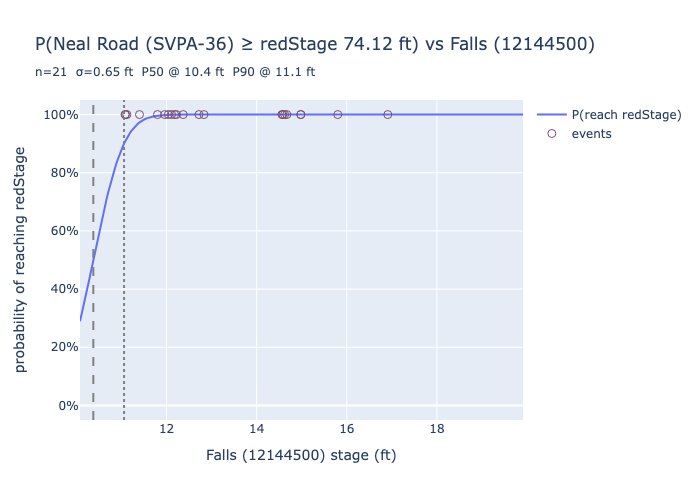

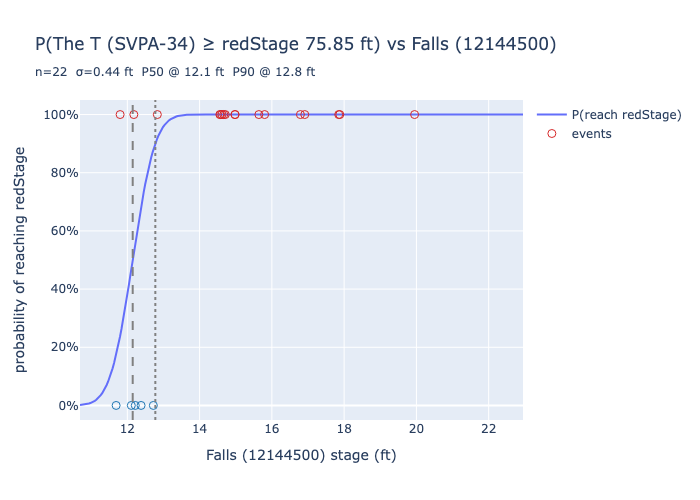

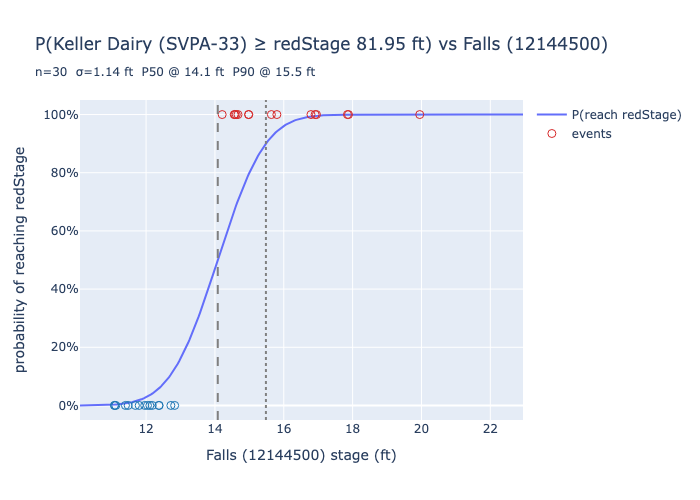

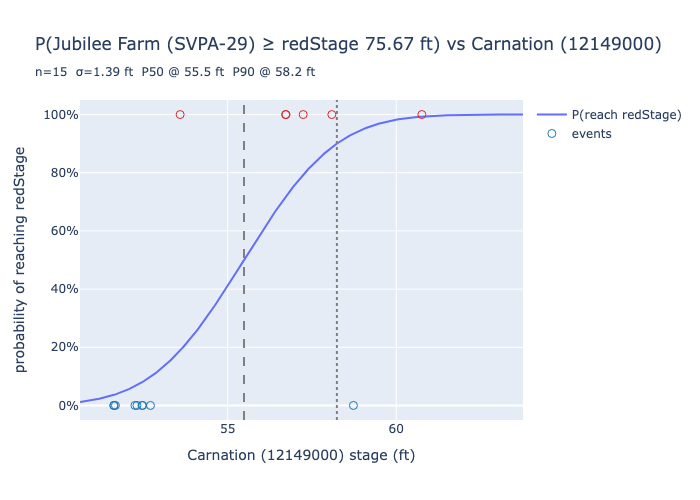

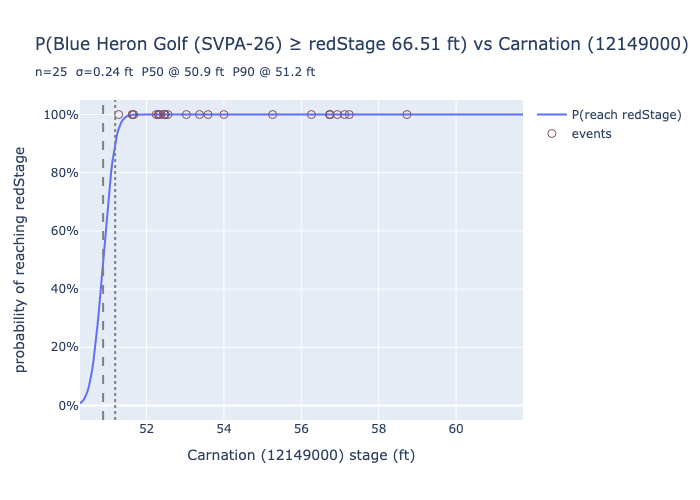

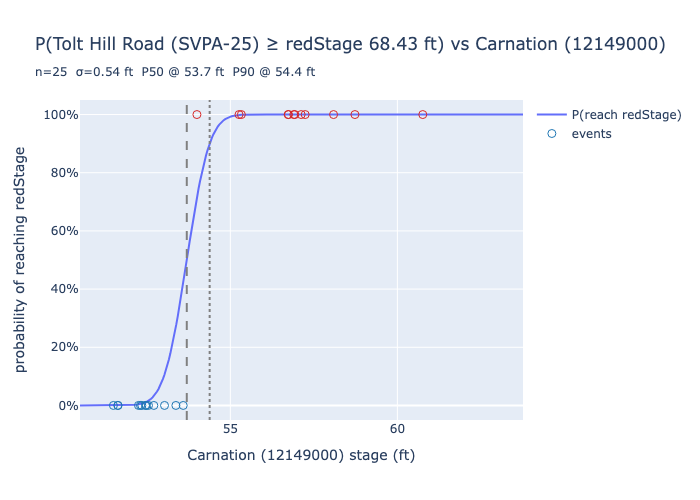

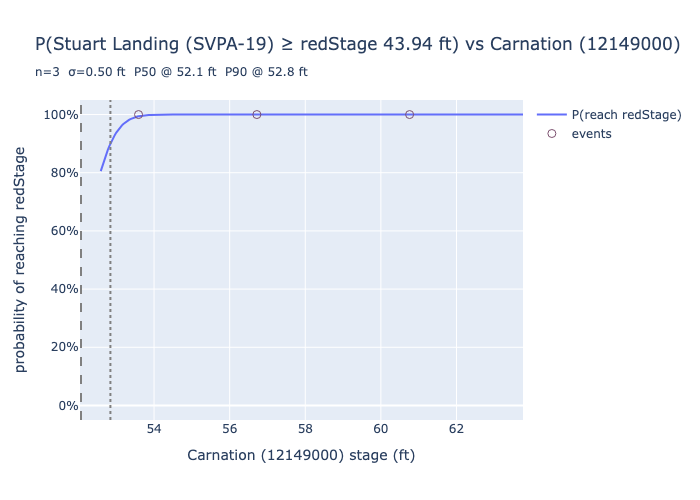

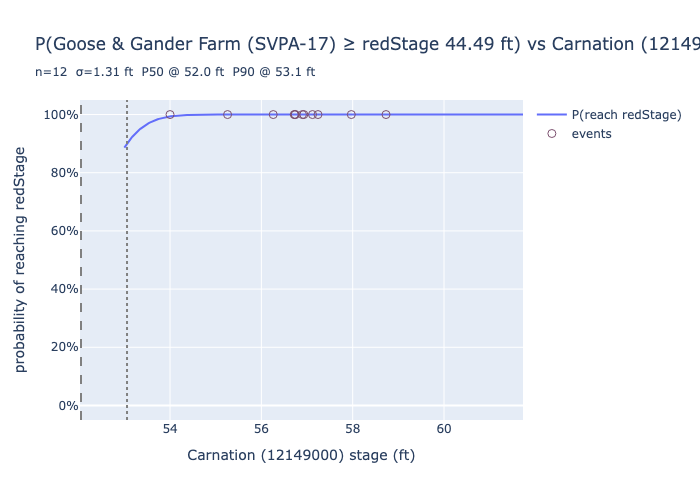

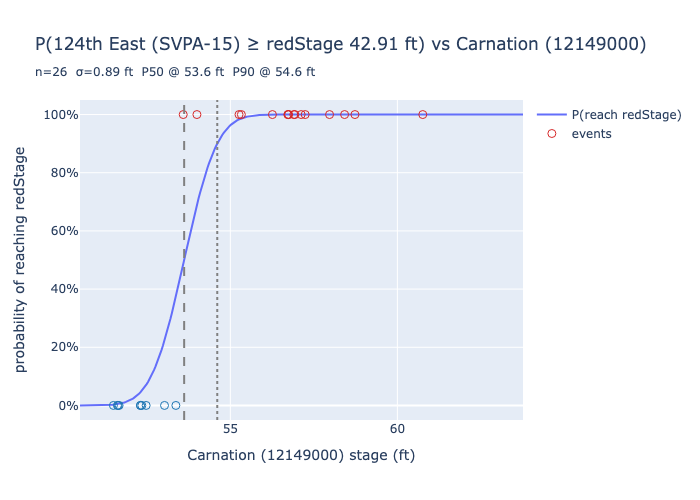

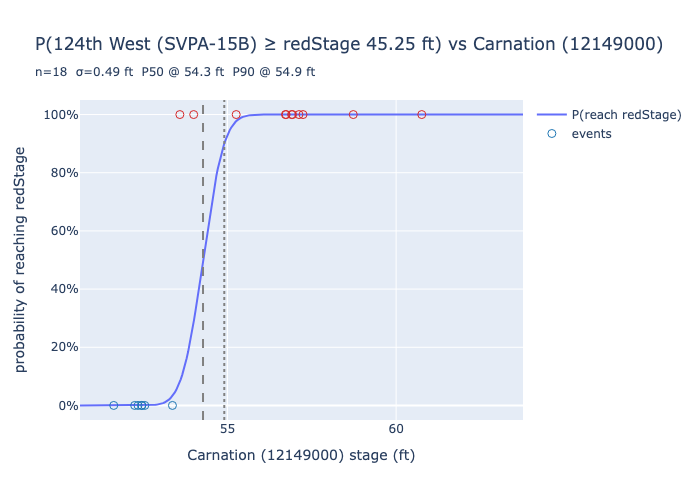

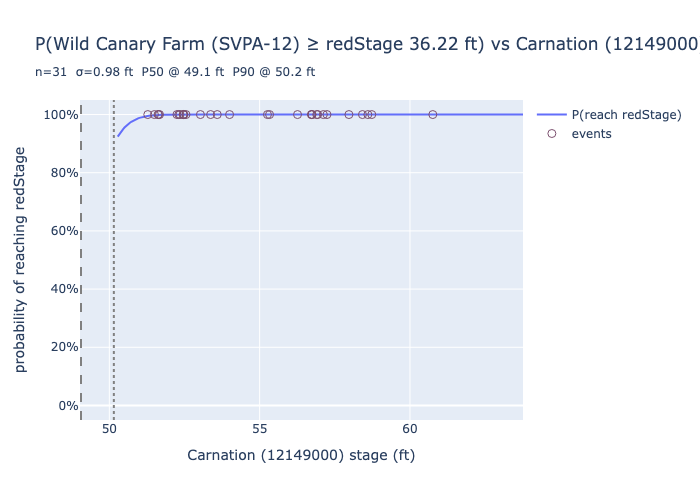

,gauge,predictor,redStage,sigma,pred_stage_P50,pred_stage_P90
0,SVPA-37,12144500,88.60,1.19,12.7,14.2
1,SVPA-36,12144500,74.12,0.65,10.4,11.1
2,SVPA-34,12144500,75.85,0.44,12.1,12.8
3,SVPA-33,12144500,81.95,1.14,14.1,15.5
4,SVPA-29,12149000,75.67,1.39,55.5,58.2
5,SVPA-26,12149000,66.51,0.24,50.9,51.2
6,SVPA-25,12149000,68.43,0.54,53.7,54.4
7,SVPA-19,12149000,43.94,0.50,52.1,52.8
8,SVPA-17,12149000,44.49,1.31,52.0,53.1
9,SVPA-15,12149000,42.91,0.89,53.6,54.6


In [8]:
prob_summary = []
for gid in svpa_gauges:
    if gid not in red_stage:
        print(f"{gid}: no redStage from API — skipping")
        continue
    pairs, predictor_id, direction = build_pairs(gid)
    if len(pairs) < 3:
        print(f"{gid}: only {len(pairs)} paired events — skipping")
        continue
    regr, _ = build_model(pairs)
    row = plot_probability_curve(regr, pairs, predictor_id, gid, red_stage[gid])
    if row:
        prob_summary.append(row)

pd.DataFrame(prob_summary)

## Corrected charts — SVPA-37 (Sno Falls Golf)

SVPA-37 has a known reading error starting **November 2022**. Checked against the
predictor (Falls), every post-Nov-2022 crest sits ~2.6 ft **below** the historic
Falls→SVPA-37 relationship, so **2.65 ft is added** to each SVPA-37 crest dated
**2022-11-01 onward**. This lifts the corrected fit from R² ≈ 0.33 (raw) to ≈ 0.99.
The main charts above are left uncorrected on purpose so the raw error stays visible.

This correction is applied *only* to SVPA-37 via the `target_correction` hook on
`build_pairs`; no other gauge is affected.

In [9]:
def correct_svpa37(df):
    """Add 2.65 ft to SVPA-37 crests dated 2022-11-01 onward.

    Post-Nov-2022 readings sit ~2.6 ft below the historic Falls->SVPA-37
    relationship; adding 2.65 ft restores the fit (R^2 0.33 -> 0.99).
    """
    df = df.copy()
    bad = df["utc"] >= pd.Timestamp("2022-11-01")
    df.loc[bad, "stage"] = df.loc[bad, "stage"] + 2.65
    return df


# Original (uncorrected) fit, for comparison.
orig_pairs, _, _ = build_pairs("SVPA-37")
orig_regr, orig_score = build_model(orig_pairs)

# Corrected fit.
pairs37, pid37, _ = build_pairs("SVPA-37", target_correction=correct_svpa37)
regr37, score37 = build_model(pairs37)

print(f"SVPA-37 uncorrected:  n={len(orig_pairs)}  R²={orig_score:.3f}")
print(f"SVPA-37 corrected:    n={len(pairs37)}  R²={score37:.3f}")

SVPA-37 uncorrected:  n=11  R²=0.787
SVPA-37 corrected:    n=11  R²=0.988


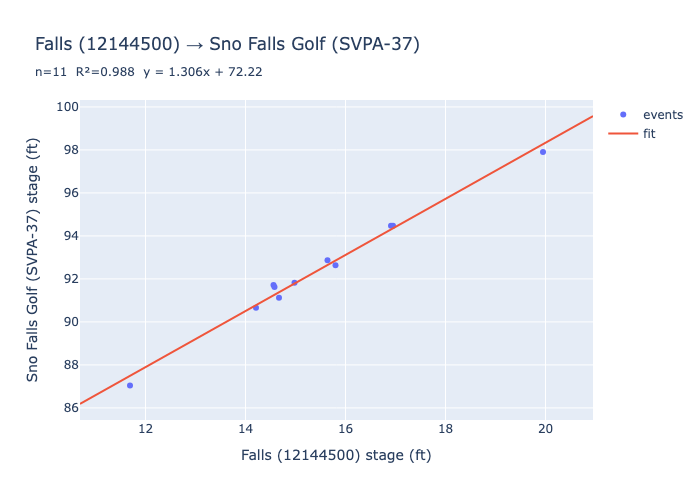

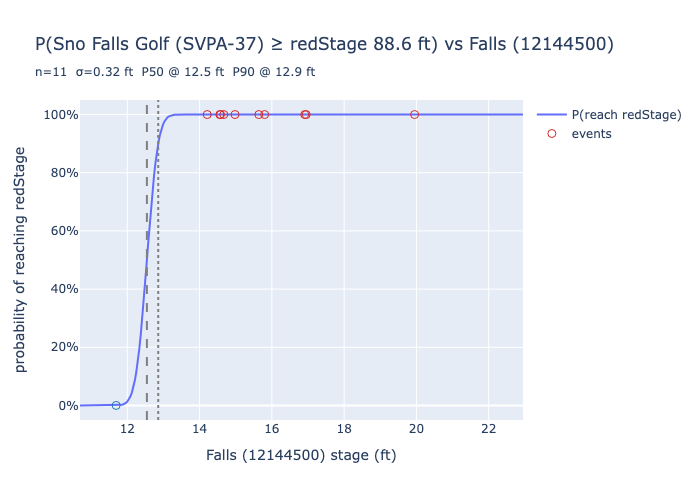

{'gauge': 'SVPA-37',
 'predictor': '12144500',
 'redStage': 88.6,
 'sigma': 0.32,
 'pred_stage_P50': np.float64(12.5),
 'pred_stage_P90': np.float64(12.9)}

In [10]:
plot_model(regr37, pairs37, pid37, "SVPA-37", score37)
plot_probability_curve(regr37, pairs37, pid37, "SVPA-37", red_stage["SVPA-37"])

## Crests under evaluation

One row per flood event (Carnation crest ≥ 51 ft) that has a matched crest at one or
more SVPA gauges. `n_gauges` is how many gauges have a crest for that event;
`n_exclusions` is how many of those are currently suppressed in
`data_files/forecast-crest-corrections.json` (with `excluded_gauges` naming them).
The `event_date` links to **SVPA-37** on the local Floodzilla site (±1 day) as a
starting point — from there step through every gauge for that crest to spot bad data.

Exclusions are configured per gauge in the JSON (gauge id → event_date → reason);
`build_pairs` drops them automatically.

In [11]:
from IPython.display import HTML

FLOODZILLA_BASE = "http://localhost:8081"


def _gage_url(gauge_id, event_date, pad_days=1):
    d = pd.Timestamp(event_date)
    frm = (d - pd.Timedelta(days=pad_days)).date()
    to = (d + pd.Timedelta(days=pad_days)).date()
    return f"{FLOODZILLA_BASE}/gage/{gauge_id}?from={frm}&to={to}"


def crest_list():
    """One row per evaluated flood event: gauge coverage and current exclusions."""
    # How many gauges have a matched crest for each event (ignore exclusions here).
    coverage = {}
    for gid in svpa_gauges:
        pairs, _, _ = build_pairs(gid, apply_exclusions=False)
        for ev in pairs["event_date"]:
            coverage[ev] = coverage.get(ev, 0) + 1

    # Which gauges currently exclude each event_date.
    excluded_by = {}
    for gid, dates in EXCLUSIONS.items():
        for d in dates:
            excluded_by.setdefault(d, []).append(gid)

    carn = events.assign(event_date=events["utc"].dt.date.astype(str))
    carn_ft = carn.groupby("event_date")["stage"].max()

    rows = []
    for ev in sorted(coverage, reverse=True):
        g = sorted(excluded_by.get(ev, []))
        rows.append({
            "event_date": ev,
            "carnation_ft": round(float(carn_ft.get(ev, np.nan)), 2),
            "n_gauges": coverage[ev],
            "n_exclusions": len(g),
            "excluded_gauges": ", ".join(s.replace("SVPA-", "") for s in g),
        })
    return pd.DataFrame(rows)


def show_crest_list():
    """crest_list() with each event_date linked to SVPA-37 on Floodzilla."""
    df = crest_list().copy()
    df["event_date"] = [
        f'<a href="{_gage_url("SVPA-37", d)}" target="_blank">{d}</a>'
        for d in df["event_date"]
    ]
    return HTML(df.to_html(escape=False, index=False))

show_crest_list()

event_date,carnation_ft,n_gauges,n_exclusions,excluded_gauges
2026-03-19,56.73,7,0,
2026-03-12,51.67,6,2,"33, 36"
2026-03-09,51.62,6,2,"15B, 25"
2025-12-18,56.72,9,0,
2025-12-16,52.71,5,0,
2025-12-11,60.76,9,0,
2025-12-10,58.09,5,4,"12, 19, 26, 36"
2025-11-15,52.48,7,0,
2025-11-02,52.31,8,0,
2025-03-25,53.59,7,1,34


In [12]:
# USGS rating tables (stage -> discharge) for the predictor gauges, used to express
# the floodProbability thresholds in flow (CFS) as well as stage. The official "exsa"
# (expanded, shift-adjusted) rating depot table is authoritative and matches what NWRFC
# uses. Columns: INDEP (gage height ft), SHIFT, DEP (discharge cfs), STOR.
def fetch_usgs_rating(site_no):
    url = ("https://nwis.waterdata.usgs.gov/nwisweb/get_ratings"
           f"?file_type=exsa&site_no={site_no}")
    text = requests.get(url, timeout=60).text
    stage, disch = [], []
    for line in text.splitlines():
        if line.startswith("#") or not line.strip():
            continue
        parts = line.split("\t")
        if parts[0] in ("INDEP", "16N"):  # column-name and format header rows
            continue
        try:
            stage.append(float(parts[0]))
            disch.append(float(parts[2]))
        except (ValueError, IndexError):
            continue
    s, d = np.array(stage), np.array(disch)
    order = np.argsort(s)
    return s[order], d[order]


RATING = {sid: fetch_usgs_rating(sid) for sid in (CARNATION_ID, FALLS_ID)}


def predictor_cfs(predictor_id, stage_ft):
    """Predictor gage height (ft) -> discharge (CFS) via the USGS rating.

    Returns None outside the rating table's range (extrapolation beyond the rating).
    """
    s, d = RATING[predictor_id]
    if stage_ft < s[0] or stage_ft > s[-1]:
        return None
    return round(float(np.interp(stage_ft, s, d)), 1)


# Rating stage coverage (min, max ft) per predictor — sanity-check vs. the p-values.
{sid: (round(float(RATING[sid][0][0]), 2), round(float(RATING[sid][0][-1]), 2))
 for sid in RATING}

{'12149000': (44.24, 61.11), '12144500': (1.35, 20.18)}

## Export predictions for Floodzilla

Writes `data_files/floodzilla-predictions.json` for import into the Floodzilla site.
Includes every gauge whose cleaned fit has **R² > 0.9**:

- **predictor** — the NWRFC-forecast USGS gauge (Floodzilla id, USGS site id, NOAA/NWRFC id).
- **regression** — `slope`, `intercept` so `predicted = slope·predictor + intercept`.
- **floodProbability** — `redStage` and residual `σ`; flood odds =
  `Φ((predicted − redStage) / σ)`. `p50/p90/p99` are the predictor **stage** thresholds,
  and `flow.p50/p90/p99` are those same thresholds as predictor **discharge (CFS)**,
  converted via the official USGS stage-discharge rating table (`null` if a threshold
  falls outside the rating range).
- **validRange.minPredictorStage** — lowest predictor stage we have data for; below this
  is extrapolation.

SVPA-37 is excluded (only clears 0.9 with the +2.65 datum correction). Note SVPA-19's
`fit.n` is small — judge it before relying on it.

> ⚠️ **The schema of this export is now consumed by code in the Floodzilla app.**
> Consumers tolerate *added* properties, so adding a new field is safe. What breaks them
> is **renaming, moving, removing, or changing the type/meaning of an existing property** —
> avoid those unless necessary, since they require a coordinated change in the app.
>
> `schemaVersion` is a dotted `"major.minor"` string: bump the **minor** when you add
> properties (e.g. `1.1` → `1.2`, as the `flow` block did), and the **major** only for a
> breaking change to existing properties.

In [13]:
import datetime as dt

_by_usgs = {str(g.get("usgsSiteId")): g for g in _info if g.get("usgsSiteId")}
PREDICTOR_META = {
    sid: {
        "floodzillaId": _by_usgs.get(sid, {}).get("id"),
        "usgsSiteId": sid,
        "noaaSiteId": _by_usgs.get(sid, {}).get("noaaSiteId"),
        "name": loc_name.get(sid, sid),
    }
    for sid in (CARNATION_ID, FALLS_ID)
}

R2_THRESHOLD = 0.9
gauges_out = []
for gid in svpa_gauges:
    pairs, predictor_id, _ = build_pairs(gid)
    if len(pairs) < 3:
        continue
    regr, r2 = build_model(pairs)
    if r2 <= R2_THRESHOLD:
        continue
    sigma = residual_sigma(regr, pairs)
    X = pairs["predictor_stage"]
    slope, intercept = float(regr.coef_[0]), float(regr.intercept_)
    red = red_stage.get(gid)
    # predictor_stage at which P(stage >= redStage) == p
    pred_at = lambda p: round((red + norm.ppf(p) * sigma - intercept) / slope, 2)
    info = next((g for g in _info if g.get("id") == gid), {})
    gauges_out.append({
        "gaugeId": gid,
        "name": loc_name.get(gid, gid),
        "redStage": red_stage.get(gid),
        "predictor": PREDICTOR_META[predictor_id],
        "regression": {
            "slope": round(float(regr.coef_[0]), 4),
            "intercept": round(float(regr.intercept_), 4),
        },
        "floodProbability": {
            "redStage": red,
            "residualSigma": round(float(sigma), 4),
            "p50": pred_at(0.5),
            "p90": pred_at(0.9),
            "p99": pred_at(0.99),
            # Same p50/p90/p99 thresholds expressed as predictor discharge (CFS),
            # via the official USGS stage-discharge rating for the predictor gauge.
            "flow": {
                "p50": predictor_cfs(predictor_id, pred_at(0.5)),
                "p90": predictor_cfs(predictor_id, pred_at(0.9)),
                "p99": predictor_cfs(predictor_id, pred_at(0.99)),
            },
        },
        "validRange": {
            "minPredictorStage": round(float(X.min()), 2),
            "maxPredictorStage": round(float(X.max()), 2),
        },
        "fit": {"r2": round(float(r2), 4), "n": int(len(pairs))},
    })

export = {
    # Dotted "major.minor". Consumers tolerate added properties, so adding fields bumps
    # only the MINOR (1.1 -> 1.2). Bump the MAJOR only for a breaking change: renaming,
    # moving, removing, or changing the type/meaning of an existing property.
    # 1.1 -> 1.2 added floodProbability.flow (predictor CFS for each p-threshold).
    "schemaVersion": "1.2",
    "generated": dt.date.today().isoformat(),
    "source": "notebooks/svpa-forecast-regression.ipynb",
    "description": ("Linear-regression predictions of SVPA gauge stage from "
                    "NWRFC-forecast USGS predictor gauges, with Gaussian flood-"
                    "probability factors. Includes gauges with fit R^2 > 0.9."),
    "method": {
        "heightPrediction": "predicted_stage = regression.slope * predictor_stage + regression.intercept",
        "floodProbability": ("P(stage >= redStage) = normalCdf((predicted_stage - "
                             "floodProbability.redStage) / floodProbability.residualSigma)"),
        "validity": ("Apply only when predictor_stage >= validRange.minPredictorStage; "
                     "below that is extrapolation beyond observed data."),
        "floodProbabilityThresholds": ("floodProbability.p50/p90/p99 are the predictor_stage "
                                       "values at which P(stage >= redStage) = 0.50/0.90/0.99."),
        "floodProbabilityFlow": ("floodProbability.flow.p50/p90/p99 are those same thresholds "
                                 "expressed as predictor discharge (CFS), converted via the "
                                 "official USGS stage-discharge rating table for the predictor "
                                 "gauge. null means the threshold is outside the rating range."),
    },
    "predictors": PREDICTOR_META,
    "gauges": gauges_out,
}

out_path = ROOT / "data_files" / "floodzilla-predictions.json"
with open(out_path, "w") as f:
    json.dump(export, f, indent=2)
    f.write("\n")
print(f"wrote {out_path} with {len(gauges_out)} gauges:",
      ", ".join(g["gaugeId"] for g in gauges_out))
export

wrote ../data_files/floodzilla-predictions.json with 8 gauges: SVPA-36, SVPA-34, SVPA-26, SVPA-25, SVPA-19, SVPA-15, SVPA-15B, SVPA-12


{'schemaVersion': '1.2',
 'generated': '2026-06-21',
 'source': 'notebooks/svpa-forecast-regression.ipynb',
 'description': 'Linear-regression predictions of SVPA gauge stage from NWRFC-forecast USGS predictor gauges, with Gaussian flood-probability factors. Includes gauges with fit R^2 > 0.9.',
 'method': {'heightPrediction': 'predicted_stage = regression.slope * predictor_stage + regression.intercept',
  'floodProbability': 'P(stage >= redStage) = normalCdf((predicted_stage - floodProbability.redStage) / floodProbability.residualSigma)',
  'validity': 'Apply only when predictor_stage >= validRange.minPredictorStage; below that is extrapolation beyond observed data.',
  'floodProbabilityThresholds': 'floodProbability.p50/p90/p99 are the predictor_stage values at which P(stage >= redStage) = 0.50/0.90/0.99.',
  'floodProbabilityFlow': 'floodProbability.flow.p50/p90/p99 are those same thresholds expressed as predictor discharge (CFS), converted via the official USGS stage-discharge rati